In [ ]:
# Titanic Survival Prediction

## Project Overview

# This project uses machine learning to predict whether a passenger survived the Titanic disaster.

# The project demonstrates:

# - Exploratory Data Analysis
# - Data preprocessing
# - Feature engineering
# - Logistic Regression
# - Model evaluation
# - ROC-AUC analysis
# - Classification threshold tuning

In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
 
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_auc_score,RocCurveDisplay)

In [4]:
df=pd.read_csv("../data/Titanic-Dataset.csv")

In [5]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
df.shape

(891, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [8]:
df.describe(include="all")

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,B96 B98,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [9]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [10]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [11]:
df[df['Cabin'].isnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
884,885,0,3,"Sutehall, Mr. Henry Jr",male,25.0,0,0,SOTON/OQ 392076,7.0500,NaN,S
885,886,0,3,"Rice, Mrs. William (Margaret Norton)",female,39.0,0,5,382652,29.1250,NaN,Q
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S


In [12]:
df['Survived'].value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [13]:
pd.crosstab(df["Sex"], df["Survived"],normalize="index")

Survived,0,1
Sex,,
female,0.257962,0.742038
male,0.811092,0.188908


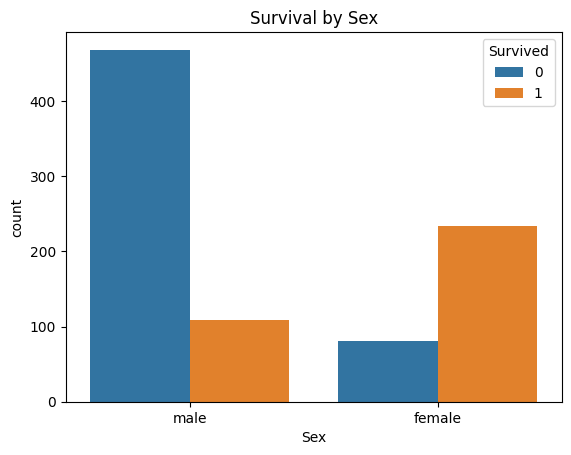

In [14]:
sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival by Sex")

plt.show()

In [15]:
pd.crosstab(df['Pclass'],df['Survived'],normalize="index")

Survived,0,1
Pclass,,
1,0.370370,0.629630
2,0.527174,0.472826
3,0.757637,0.242363


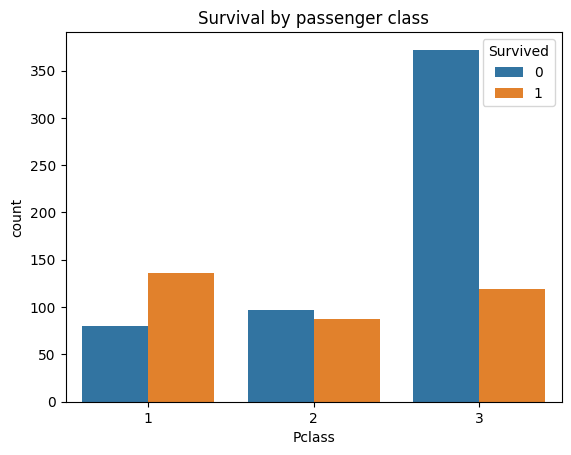

In [16]:
sns.countplot(data=df,x='Pclass',hue="Survived")
plt.title("Survival by passenger class")
plt.show()

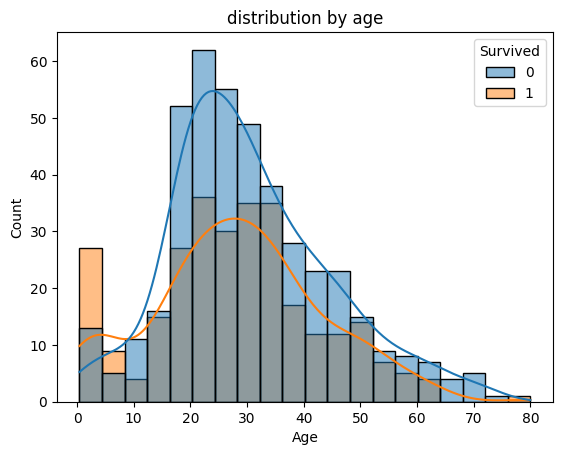

In [17]:
sns.histplot(data=df,x='Age',hue="Survived",kde=True)
plt.title("distribution by age")
plt.show()

In [18]:
features=["Pclass","Sex","Age","SibSp","Parch","Fare","Embarked"]
target="Survived"
x=df[features]
y=df[target]


In [19]:
x.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [20]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [21]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=8,stratify=y)

In [22]:
numerical_features=['Pclass','Age','SibSp','Parch','Fare']
categorical_features=['Sex','Embarked']

In [23]:
numerical_pipeline=Pipeline([("imputer",SimpleImputer(strategy="median")),(("scaler",StandardScaler()))])
categorical_pipeline=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),(("encoder",OneHotEncoder(handle_unknown="ignore")))])

In [24]:
preprocessor=ColumnTransformer([("num",numerical_pipeline,numerical_features),("category",categorical_pipeline,categorical_features)])


In [25]:
model=Pipeline([("preprocessor",preprocessor),("classifier",LogisticRegression())])
model.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('category', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [26]:
y_pred=model.predict(x_test)

In [27]:
print(y_pred[:20])

[1 1 0 0 0 1 0 0 0 0 0 1 0 0 1 1 0 1 1 1]


In [28]:
cr= classification_report(y_test,y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.88      0.88      0.88       110
           1       0.81      0.81      0.81        69

    accuracy                           0.85       179
   macro avg       0.85      0.85      0.85       179
weighted avg       0.85      0.85      0.85       179



In [29]:
accuracy=accuracy_score(y_test,y_pred)
accuracy

0.8547486033519553

In [30]:
cm= confusion_matrix(y_test,y_pred)
cm

array([[97, 13],
       [13, 56]])

In [31]:
y_probability=model.predict_proba(x_test)[:,1]
auc=roc_auc_score(y_test,y_probability)
print(auc)

0.9043478260869564


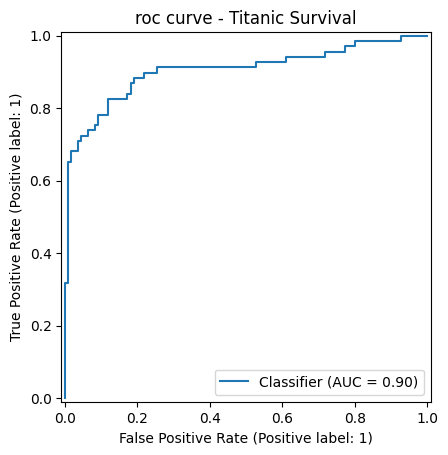

In [32]:
RocCurveDisplay.from_predictions(y_test,y_probability)
plt.title("roc curve - Titanic Survival")
plt.show()

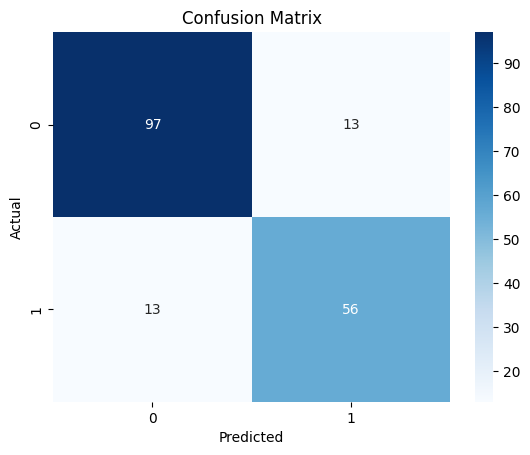

In [33]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [34]:
# Feature engineering , building new features 



df['FamilySize']= df['SibSp']+df['Parch'] +1

In [35]:
df[['SibSp',"Parch","FamilySize"]].head(10)

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1
5,0,0,1
6,0,0,1
7,3,1,5
8,0,2,3
9,1,0,2


In [36]:
df['IsAlone']= (df['FamilySize']==1).astype(int)

In [37]:
df[['FamilySize','IsAlone']].head(10)

,FamilySize,IsAlone
0,2,0
1,2,0
2,1,1
3,2,0
4,1,1
5,1,1
6,1,1
7,5,0
8,3,0
9,2,0


In [38]:
df['Name'].head(10)

0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry
5                                     Moran, Mr. James
6                              McCarthy, Mr. Timothy J
7                       Palsson, Master. Gosta Leonard
8    Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)
9                  Nasser, Mrs. Nicholas (Adele Achem)
Name: Name, dtype: object

In [39]:
df['Title']=df['Name'].str.extract(r',\s*([^.]*)\.')

In [40]:
df['Title'].head()

0      Mr
1     Mrs
2    Miss
3     Mrs
4      Mr
Name: Title, dtype: object

In [41]:
df['Title'].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Mlle              2
Major             2
Col               2
the Countess      1
Capt              1
Ms                1
Sir               1
Lady              1
Mme               1
Don               1
Jonkheer          1
Name: count, dtype: int64

In [42]:
df['Deck']=df['Cabin'].str[0]

In [43]:
df['Cabin']

0       NaN
1       C85
2       NaN
3      C123
4       NaN
       ... 
886     NaN
887     B42
888     NaN
889    C148
890     NaN
Name: Cabin, Length: 891, dtype: object

In [44]:
df['Deck']=df['Deck'].fillna("Unknown")

In [45]:
df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize,IsAlone,Title,Deck
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,0,Mr,Unknown
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,0,Mrs,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,1,Miss,Unknown
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,0,Mrs,C
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,1,Mr,Unknown


In [46]:
df=df.drop(columns=['PassengerId','Name','Ticket','Cabin'])

In [47]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title,Deck
0,0,3,male,22.0,1,0,7.2500,S,2,0,Mr,Unknown
1,1,1,female,38.0,1,0,71.2833,C,2,0,Mrs,C
2,1,3,female,26.0,0,0,7.9250,S,1,1,Miss,Unknown
3,1,1,female,35.0,1,0,53.1000,S,2,0,Mrs,C
4,0,3,male,35.0,0,0,8.0500,S,1,1,Mr,Unknown
...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,1,1,Rev,Unknown
887,1,1,female,19.0,0,0,30.0000,S,1,1,Miss,B
888,0,3,female,NaN,1,2,23.4500,S,4,0,Miss,Unknown
889,1,1,male,26.0,0,0,30.0000,C,1,1,Mr,C


In [48]:
pd.crosstab(df['FamilySize'],df['Survived'],normalize="index")

Survived,0,1
FamilySize,,
1,0.696462,0.303538
2,0.447205,0.552795
3,0.421569,0.578431
4,0.275862,0.724138
5,0.800000,0.200000
6,0.863636,0.136364
7,0.666667,0.333333
8,1.000000,0.000000
11,1.000000,0.000000


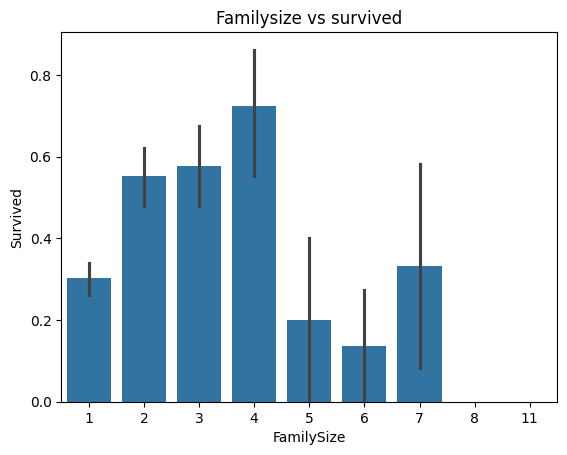

In [49]:
sns.barplot(data=df,x="FamilySize",y="Survived")
plt.title("Familysize vs survived")
plt.show()

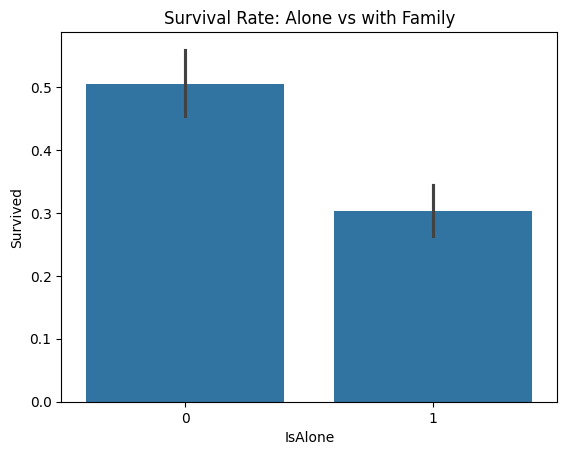

In [50]:
sns.barplot(data=df,x='IsAlone',y="Survived")
plt.title("Survival Rate: Alone vs with Family")
plt.show()

In [51]:
df['IsAlone'].value_counts()

IsAlone
1    537
0    354
Name: count, dtype: int64

In [52]:
# rebuild x and y 
y=df['Survived']
x=df.drop('Survived',axis=1)

In [53]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Pclass      891 non-null    int64  
 1   Sex         891 non-null    object 
 2   Age         714 non-null    float64
 3   SibSp       891 non-null    int64  
 4   Parch       891 non-null    int64  
 5   Fare        891 non-null    float64
 6   Embarked    889 non-null    object 
 7   FamilySize  891 non-null    int64  
 8   IsAlone     891 non-null    int64  
 9   Title       891 non-null    object 
 10  Deck        891 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


In [54]:
x.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title,Deck
0,3,male,22.0,1,0,7.2500,S,2,0,Mr,Unknown
1,1,female,38.0,1,0,71.2833,C,2,0,Mrs,C
2,3,female,26.0,0,0,7.9250,S,1,1,Miss,Unknown
3,1,female,35.0,1,0,53.1000,S,2,0,Mrs,C
4,3,male,35.0,0,0,8.0500,S,1,1,Mr,Unknown


In [55]:
numerical_features=['Pclass','Age','SibSp','Parch','Fare',"FamilySize","IsAlone"]
categorical_features=['Sex',"Embarked","Title","Deck"]

In [56]:
numerical_pipeline=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())])
categorical_pipeline=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("encoder",OneHotEncoder(handle_unknown="ignore"))])

In [57]:
preprocessor=ColumnTransformer([("num",numerical_pipeline,numerical_features),("cat",categorical_pipeline,categorical_features)])

In [58]:
model_improved=Pipeline([("preprocessor",preprocessor),("regressor",LogisticRegression(max_iter=1000))])

In [59]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=8,stratify=y)

In [60]:
model_improved.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [61]:
y_pred2=model_improved.predict(x_test)

In [62]:
clr=classification_report(y_test,y_pred2)
print(clr)

              precision    recall  f1-score   support

           0       0.87      0.87      0.87       110
           1       0.80      0.80      0.80        69

    accuracy                           0.84       179
   macro avg       0.83      0.83      0.83       179
weighted avg       0.84      0.84      0.84       179



In [63]:
y_probability2=model_improved.predict_proba(x_test)[:,1]
roc_auc_score2=roc_auc_score(y_test,y_probability2)
roc_auc_score2

0.9023715415019764

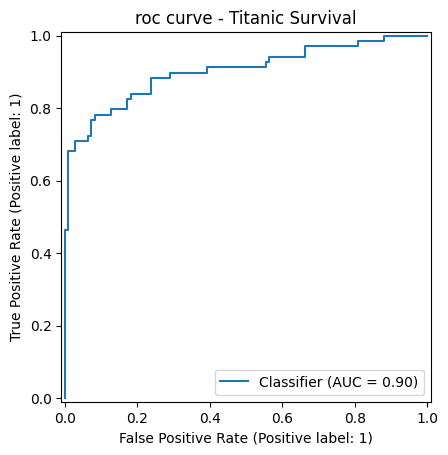

In [64]:
RocCurveDisplay.from_predictions(y_test,y_probability2)
plt.title("roc curve - Titanic Survival")
plt.show()

In [65]:
results= pd.DataFrame({
    "model":[
        "baseline logistic regression",
        "feature engineered logistic regression"
    ],
    "classification report":[
        cr,
        clr
        ],
        "ruc score":[
            auc,
            roc_auc_score2
        ]
})

In [66]:
pd.set_option('display.max_colwidth', None)   # don't truncate the text
pd.set_option('display.max_rows', None)

results.style.set_properties(**{'white-space': 'pre-wrap'})

,model,classification report,ruc score
0,baseline logistic regression,precision recall f1-score support 0 0.88 0.88 0.88 110 1 0.81 0.81 0.81 69 accuracy 0.85 179 macro avg 0.85 0.85 0.85 179 weighted avg 0.85 0.85 0.85 179,0.904348
1,feature engineered logistic regression,precision recall f1-score support 0 0.87 0.87 0.87 110 1 0.80 0.80 0.80 69 accuracy 0.84 179 macro avg 0.83 0.83 0.83 179 weighted avg 0.84 0.84 0.84 179,0.902372


In [67]:
# threshold tuning
resultss=[]
for threshold in [0.3,0.4,0.5,0.6,0.7]:
    predictions=(y_probability2>threshold).astype(int)

    resultss.append(
      {  "threshold":threshold,
        "precision":round(precision_score(y_test,predictions),3),
        "recall":round(recall_score(y_test,predictions),3),
        "F1 score":round(f1_score(y_test,predictions),3)
        }
    )

results_df=pd.DataFrame(resultss)
results_df


,threshold,precision,recall,F1 score
0,0.3,0.690,0.841,0.758
1,0.4,0.750,0.826,0.786
2,0.5,0.797,0.797,0.797
3,0.6,0.877,0.725,0.794
4,0.7,0.959,0.681,0.797
